In [ ]:
import sys
sys.path.insert(0,'../CRLDenv/lib/python3.11/site-packages')
print(sys.path)

['../CRLDenv/lib/python3.11/site-packages', '/home/clemence/Documents/PhD/Code/DistRLdynamics', '/usr/lib/python39.zip', '/usr/lib/python3.9', '/usr/lib/python3.9/lib-dynload', '', '/home/clemence/Documents/PhD/Code/pyCRLD/CRLDenv/lib/python3.9/site-packages']


In [ ]:
import numpy as np
from scipy.stats import norm

import jax.numpy as jnp
from jax import jit
from functools import partial

from pyCRLD.Agents.Base import abase
from pyCRLD.Utils.Helpers import *

import pandas as pd
# import seaborn as sns

In [ ]:
from pyCRLD.Environments.SocialDilemma import SocialDilemma
from pyCRLD.Environments.RiskRewardDilemma import RiskRewardDilemma
from pyCRLD.Environments.DistTwoArmedBanditOneState import DistTwoArmedBanditOneState
from pyCRLD.Agents.StrategySARSA import stratSARSA
from qBaseDistR import qbaseDist
from qBaseSARSA import qbaseSARSA
from pyCRLD.Utils.Trajectories1D import trajectories_1D 
from pyCRLD.Utils.PhasePlot import phaseplot
import matplotlib.pyplot as plt

In [ ]:
import matplotlib as mpl
from pyCRLD.Utils.PhasePlot import phaseplot, _data_to_plot, _strategies, _dXisa_s

In [ ]:
def compare_envs(rt_list,  # level list
                 method,  # used method
                 w,
                 gamma,
                 beta,
                 Rmin,
                 Rmax,
                 x:tuple,  # which phase space axes to plot along x axes
                 res,  # specify range & resolution
                 nrb:int=29,
                 discsig:float=0.05,
                 lr:float=0.1,
                 NrRandom:int=4,  # how many random (in the other dimensions) stratgies for averaging 
                 traj_len:int=500,  # trajectory length
                 cmap='viridis',  # Colormap
                 acts=None,  # Action descriptions
                 conds=None,  # Conditions descriptions 
                 axes=None,  # Axes to plot into
                 verbose=False,  # shall I talk to you while working?
                 ):  
   

    # Fig and Axes
    states = 1
    fig, ax = plt.subplots(1, 1, figsize=(3.8, 3.8))
    cmap = mpl.cm.get_cmap(cmap)
    ext = np.linspace(0, 1, len(rt_list))
    colors = cmap(tuple(ext))
    
    # x axis
    xs = res
    zero = np.zeros((len(xs)))

    # The Plots
    for j, l in enumerate(rt_list):
        print(l)
        if method=='weights':
            env = SocialDilemma(R=l, S=-2, T=4-l, P=0)
            mae = qbaseSARSA(env, nr_reward_bins=nrb, discretization_sigma=discsig, 
                             learning_rates=lr, discount_factors=gamma, 
                             choice_intensities=beta, Rmin=Rmin, Rmax=Rmax,
                             method=method, wU=w, use_prefactor=True)
                             
        elif method=='expectile':
            env = SocialDilemma(R=l, S=-2, T=4-l, P=0)
            mae = qbaseSARSA(env, nr_reward_bins=nrb, discretization_sigma=discsig, 
                             learning_rates=lr, discount_factors=gamma, 
                             choice_intensities=beta, Rmin=Rmin, Rmax=Rmax,
                             method=method, tau=l, use_prefactor=True)
            
        xinds = (x[0][0], x[1][0], x[2][0])  # fix this later
            
        # obtain the data to plot
        RPEs, dXs = _data_to_plot(mae, res, xinds, traj_len, NrRandom, 
                                  phasespace_items=_strategies, verbose=verbose)
        ax.plot(xs, dXs[0, :], color=colors[j], label=r'$R=$'+str(l))
        ax.plot(xs, zero, color="grey", ls='dashed')
        
    ax.set_ylabel(r"$dX$")
    ax.set_xlabel(r'$X^{0}_{00}$')
    ax.set_title('phase plot')
    ax.legend(bbox_to_anchor=(1.01, 1.01))
    
    # return fig

In [ ]:
x = ([0], [0], [0])  # probability of cooperating for agent 1
res = np.linspace(0, 1., 21)
res[0] = 0.0001
res[-1] = 0.9999

In [ ]:
rt_list = np.array([1., 1.5, 1.99, 2., 2.01, 2.5, 3.])

/tmp/ipykernel_5583/3416131042.py:25: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = mpl.cm.get_cmap(cmap)


1.0
1.5
1.99
2.0
2.01
2.5
3.0


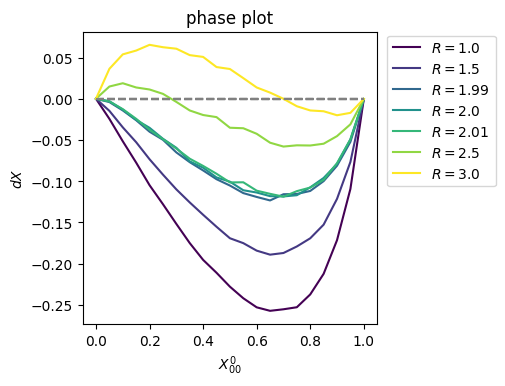

In [ ]:
compare_envs(rt_list, method='weights', w=4, gamma=0.9, beta=50, Rmin=-2, Rmax=3, x=x, res=res, NrRandom=100)

In [ ]:
rt_list = np.array([2.,2.1, 2.2, 2.3, 2.4])

/tmp/ipykernel_5583/3424226454.py:26: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = mpl.cm.get_cmap(cmap)


2.0
2.1
2.2
2.3
2.4


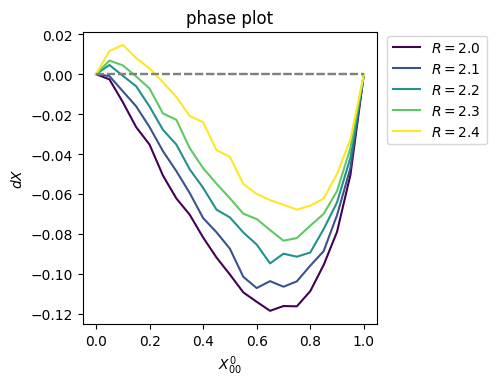

In [ ]:
compare_envs(rt_list, method='weights', w=4, gamma=0.9, beta=50, Rmin=-2, Rmax=3, x=x, res=res, NrRandom=100)